In [1]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

In [2]:
BATCH_SIZE = 128
EPOCHS = 10
LEARNING_RATE = 0.001

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

classes = (
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
)

In [3]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose(
    [
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ]
)
test_transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize(mean, std)]
)

train_dataset = torchvision.datasets.CIFAR10(
    root="./", train=True, download=False, transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./", train=False, download=False, transform=test_transform
)

train_loader = DataLoader(
    train_dataset, shuffle=True, batch_size=BATCH_SIZE, num_workers=2
)

test_loader = DataLoader(
    test_dataset, shuffle=False, batch_size=BATCH_SIZE, num_workers=2
)

In [ ]:
class CNNClassifer(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Input: (N, 3, 32, 32)
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            # (N, 32, 16, 16)
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            # Output: (N, 64, 8, 8)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [5]:
model = CNNClassifer().to(device)

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=5e-4)
loss_fn = nn.CrossEntropyLoss()

epoch_losses = []
epoch_accuracies = []

for epoch in range(EPOCHS):
    model.train()

    epoch_total_loss = 0.0
    epoch_total = 0
    epoch_correct = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = loss_fn(logits, labels)

        loss.backward()
        optimizer.step()

        predictions = logits.argmax(axis=1)

        epoch_total_loss += loss.item() * images.size(0)
        epoch_total += len(labels)
        epoch_correct += (labels == predictions).sum().item()

    epoch_loss = epoch_total_loss / epoch_total
    epoch_accuracy = 100 * epoch_correct / epoch_total

    epoch_losses.append(epoch_loss)
    epoch_accuracies.append(epoch_accuracy)

    print(f"Epoch: {epoch+1}, Loss: {epoch_loss}, Accuracy: {epoch_accuracy}")

Epoch: 1, Loss: 1.726065696029663, Accuracy: 36.314
Epoch: 2, Loss: 1.4628703795623779, Accuracy: 46.246
Epoch: 3, Loss: 1.369620645751953, Accuracy: 50.44
Epoch: 4, Loss: 1.3073712506866455, Accuracy: 52.642
Epoch: 5, Loss: 1.2630398740005493, Accuracy: 54.686
Epoch: 6, Loss: 1.2267339525985719, Accuracy: 56.022
Epoch: 7, Loss: 1.1990375704193115, Accuracy: 57.046
Epoch: 8, Loss: 1.183604283180237, Accuracy: 57.69
Epoch: 9, Loss: 1.1577519549560547, Accuracy: 58.818
Epoch: 10, Loss: 1.1383060383987427, Accuracy: 59.34


In [6]:
model.eval()

total = 0
total_correct = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        predictions = logits.argmax(axis=1)

        total += len(labels)
        total_correct += (labels == predictions).sum().item()

accuracy = 100 * total_correct / total
print("Test Accuracy:", accuracy)

Test Accuracy: 68.34


In [7]:
torch.save(model.state_dict(), "model_state.pth")
print("Model saved")

Model saved


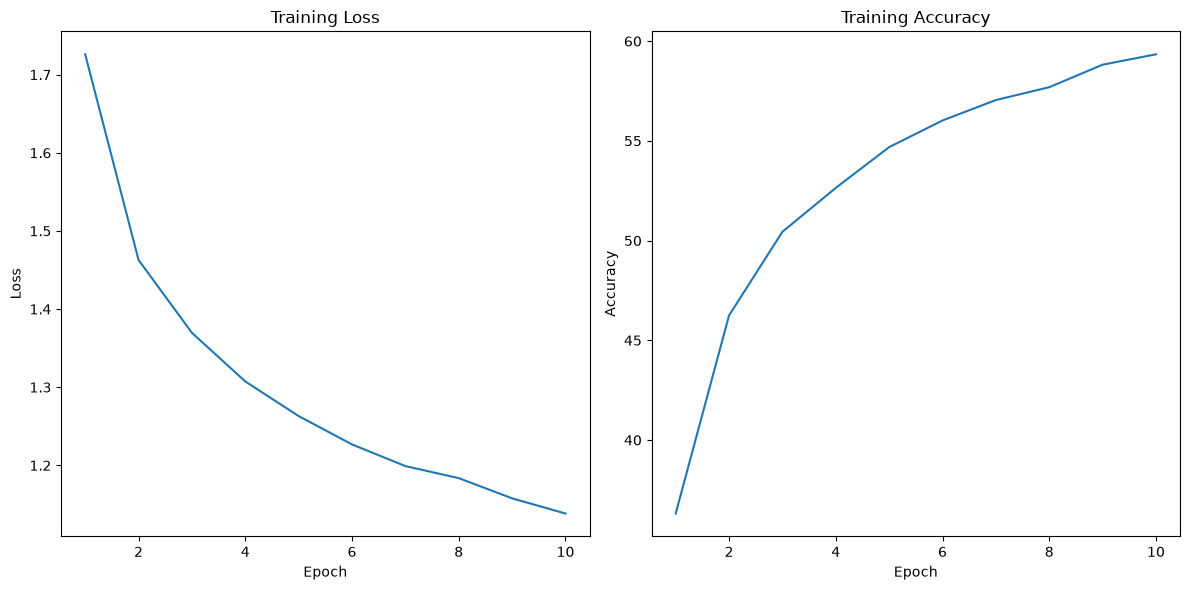

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].plot(range(1, EPOCHS + 1), epoch_losses)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training Loss")

axes[1].plot(range(1, EPOCHS + 1), epoch_accuracies)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training Accuracy")

plt.tight_layout()
plt.show()